In [1]:
import pandas as pd 
import numpy as np
from sklearn.datasets import load_breast_cancer

# Step 1 : Prepare the Data for Machine Learning

In [2]:
# load dataset 
data = load_breast_cancer()

In [3]:
# Create dataframe 
df = pd.DataFrame(data.data, columns=data.feature_names)

In [4]:
# Add target 
df["target"] = data.target

### What is X?
#### ---> X contains the independent variables or input features used by the machine-learning model to make predictions. In our project, X contains 30 numerical characteristics of cell nuclei.

In [5]:
#Separate features
X = df.drop("target", axis = 1)

### What is y?
#### ---> y is the dependent variable or target variable that the model learns to predict. In our project, it represents whether the sample is benign or malignant.

### Convert sklearn target
0 = malignant, 1 = benign 
We want :- 0 = benign, 1 = malignant

In [6]:
#Separate target 
y = 1 - df["target"]

#### Verification

In [7]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


In [8]:
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget meaning:")
print("0 = Benign")
print("1 = Malignant")


Target distribution:
target
0    357
1    212
Name: count, dtype: int64

Target meaning:
0 = Benign
1 = Malignant


### Why did you convert the target?
#### ---> The original scikit-learn dataset encodes malignant as 0 and benign as 1. We changed it to benign = 0 and malignant = 1 so that malignant becomes the positive class, making metrics such as recall/sensitivity easier to interpret in our medical classification context.

# Step 2 : Train/Test Split

                 569 samples
                     │
             Train/Test Split
                 /       \
                /         \
               ↓           ↓
          Training       Testing
           80%             20%
        ≈ 455 samples    ≈ 114 samples

#### Benign = 357 Malignant = 212  ---> they are not equal
#### If we randomly split without considering the classes, we could theoretically get an undesirable class distribution in the train/test sets.    
#### Therefore we will use "stratify=y" 
#### This tells scikit-learn:
#### Keep approximately the same proportion of benign and malignant samples in both training and testing sets.

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

In [11]:
# Verification
print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

Training set:
X_train: (455, 30)
y_train: (455,)


In [12]:
print("Testing set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Testing set:
X_test: (114, 30)
y_test: (114,)


In [13]:
print("Training class distribution:")
print(y_train.value_counts())

Training class distribution:
target
0    285
1    170
Name: count, dtype: int64


In [14]:
print("Testing class distribution:")
print(y_test.value_counts())

Testing class distribution:
target
0    72
1    42
Name: count, dtype: int64


# Step 3 : Preprocessing + Pipelines

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

### Creating pipelines for scale-sensitive models

#### Logistic Regression

In [16]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()), 
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

#### KNN  

In [17]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()), 
    ("model", KNeighborsClassifier())
])

#### SVM -->  Support Vector Machine

In [18]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", CalibratedClassifierCV(
        SVC(random_state=42),
        ensemble=False
    ))
])

### Creating pipelines for tree models

#### Decision Tree

In [19]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(random_state=42)

#### Random Forest

In [20]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(random_state=42)

In [21]:
print(logistic_pipeline)
print(knn_pipeline)
print(svm_pipeline)
print(decision_tree)
print(random_forest)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])
Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier())])
Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 CalibratedClassifierCV(ensemble=False,
                                        estimator=SVC(random_state=42)))])
DecisionTreeClassifier(random_state=42)
RandomForestClassifier(random_state=42)


# Step 4 : Baseline Model Training

In [22]:
# Train Logistic Regression 
logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [23]:
y_pred_logistic = logistic_pipeline.predict(X_test)
y_prob_logistic = logistic_pipeline.predict_proba(X_test)[:, 1]

In [24]:
#  Train KNN 
knn_pipeline.fit(X_train, y_train)

y_pred_knn = knn_pipeline.predict(X_test)
y_prob_knn = knn_pipeline.predict_proba(X_test)[:,1]

In [25]:
# Train SVM
svm_pipeline.fit(X_train, y_train)

y_pred_svm = svm_pipeline.predict(X_test)
y_prob_svm = svm_pipeline.predict_proba(X_test)[:,1]

In [26]:
# Train Decision Tree
decision_tree.fit(X_train, y_train)

y_pred_tree = decision_tree.predict(X_test)
y_prob_tree = decision_tree.predict_proba(X_test)[:,1]

In [27]:
# Train Random Forest
random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)
y_prob_rf = random_forest.predict_proba(X_test)[:,1]

In [28]:
# Verify
print("Logistic Rregression:", y_pred_logistic[:10])
print("KNN:", y_pred_knn[:10])
print("SVM:", y_pred_svm[:10])
print("Decision Tree:", y_pred_tree[:10])
print("Random Forest:", y_pred_rf[:10])

Logistic Rregression: [0 1 0 1 1 0 1 0 0 0]
KNN: [0 1 0 0 0 0 1 0 0 0]
SVM: [0 1 0 0 0 0 1 0 0 0]
Decision Tree: [0 1 1 1 0 0 1 0 0 0]
Random Forest: [0 1 0 1 0 0 1 0 0 0]


# Step 5 : Baseline Model Comparison

In [29]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

In [30]:
predictions = {
    "Logistic Regression": (y_pred_logistic, y_prob_logistic),
    "KNN": (y_pred_knn, y_prob_knn),
    "SVM": (y_pred_svm, y_prob_svm),
    "Decision Tree": (y_pred_tree, y_prob_tree),
    "Random Forest": (y_pred_rf, y_prob_rf)
}

In [31]:
# Calculate the metrics
results = []

for model_name, (y_pred, y_prob) in predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })
results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.964912,0.975000,0.928571,0.951220,0.996032
1,KNN,0.956140,0.974359,0.904762,0.938272,0.982308
2,SVM,0.973684,0.975610,0.952381,0.963855,0.994709
3,Decision Tree,0.929825,0.904762,0.904762,0.904762,0.924603
4,Random Forest,0.973684,1.000000,0.928571,0.962963,0.992890


In [32]:
best_accuracy = results_df.loc[
    results_df["Accuracy"].idxmax(), "Model"
]

best_recall = results_df.loc[
    results_df["Recall"].idxmax(), "Model"
]

best_auc = results_df.loc[
    results_df["ROC-AUC"].idxmax(), "Model"
]

print("Best Accuracy:", best_accuracy)
print("Best Recall:", best_recall)
print("Best ROC-AUC:", best_auc)

Best Accuracy: SVM
Best Recall: SVM
Best ROC-AUC: Logistic Regression


# Step 6 : Cross-Validation

In [33]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [34]:
cv = StratifiedKFold(
    n_splits=5, 
    shuffle=True,
    random_state=42
)

In [35]:
models = {
    "Logistic Regression": logistic_pipeline,
    "KNN": knn_pipeline,
    "SVM": svm_pipeline,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest
}

In [36]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [37]:
cv_results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": model_name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy SD": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean(),
        "ROC-AUC Mean": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,Model,Accuracy Mean,Accuracy SD,Precision Mean,Recall Mean,F1 Mean,ROC-AUC Mean
0,Logistic Regression,0.973626,0.014906,0.977143,0.952941,0.964048,0.995769
1,KNN,0.964835,0.018906,0.987500,0.917647,0.951042,0.987100
2,SVM,0.975824,0.008223,0.977292,0.958824,0.967043,0.994943
3,Decision Tree,0.923077,0.032599,0.899593,0.894118,0.896184,0.917234
4,Random Forest,0.964835,0.014579,0.964095,0.941176,0.951945,0.988906


#### SVM currently provides the strongest overall cross-validation performance, while Logistic Regression achieves a marginally higher mean ROC-AUC.

# Step 7 : Hyperparameter Tuning

Based on our CV results:

1. SVM 
2. Logistic Regression
3. Random Forest

### Part A: Tune SVM

In [38]:
from sklearn.model_selection import GridSearchCV

svm_param_grid = {
    "model__estimator__C": [0.1, 1, 10, 100],
    "model__estimator__kernel": ["linear", "rbf"], 
    "model__estimator__gamma": ["scale", "auto"]
}

In [39]:
# GridSearchCV
svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid, 
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._state=42)))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__estimator__C': [0.1, 1, ...], 'model__estimator__gamma': ['scale', 'auto'], 'model__estimator__kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 S

In [40]:
# finding best parameters
print("Best SVM parameters:")
print(svm_grid.best_params_)

print("\nBest cross-validation recall:")
print(svm_grid.best_score_)

Best SVM parameters:
{'model__estimator__C': 10, 'model__estimator__gamma': 'scale', 'model__estimator__kernel': 'rbf'}

Best cross-validation recall:
0.9647058823529411


### Part B: Tune Logistic Regression

In [41]:
logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

In [42]:
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informati

In [43]:
#  finding best parameters
print("Best Logistic Regression parameters:")
print(logistic_grid.best_params_)

print("\nBest cross-validation recall:")
print(logistic_grid.best_score_)

Best Logistic Regression parameters:
{'model__C': 1}

Best cross-validation recall:
0.9529411764705882


### Part C : Tune Random Forest

In [44]:
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

In [45]:
rf_grid = GridSearchCV(
    estimator=random_forest,
    param_grid=rf_param_grid,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Sup

In [46]:
# finding best parameters
print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("\nBest cross-validation recall:")
print(rf_grid.best_score_)

Best Random Forest parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}

Best cross-validation recall:
0.9470588235294117


# Step 8 : Evaluate the tuned models on the test set

Now we're going to use the test set once for final evaluation of the selected/tuned candidates.

In [47]:
# Tuned SVM 
best_svm = svm_grid.best_estimator_

y_pred_svm_tuned = best_svm.predict(X_test)
y_prob_svm_tuned = best_svm.predict_proba(X_test)[:, 1]

# Tuned Logistic Regression 
best_logistic = logistic_grid.best_estimator_

y_pred_logistic_tuned = best_logistic.predict(X_test)
y_prob_logistic_tuned = best_logistic.predict_proba(X_test)[:, 1]

# Tuned Random Forest
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)
y_prob_rf_tuned = best_rf.predict_proba(X_test)[:, 1]

In [48]:
# Calculation of final test metrics 
tuned_predictions = {
    "Tuned Logistic Regression": (
        y_pred_logistic_tuned,
        y_prob_logistic_tuned
    ),
    "Tuned SVM": (
        y_pred_svm_tuned,
        y_prob_svm_tuned
    ),
    "Tuned Random Forest": (
        y_pred_rf_tuned,
        y_prob_rf_tuned
    )
}

In [49]:
# tuned results 
tuned_results = []

for model_name, (y_pred, y_prob) in tuned_predictions.items():

    tuned_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Logistic Regression,0.964912,0.975,0.928571,0.951220,0.996032
1,Tuned SVM,0.973684,1.000,0.928571,0.962963,0.992725
2,Tuned Random Forest,0.973684,1.000,0.928571,0.962963,0.994709


# Step 9 : Feature Selection

In [50]:
print("Total number of features:", X_train.shape[1])

Total number of features: 30


In [51]:
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression

In [58]:
feature_selector = SelectFromModel(
    LogisticRegression(
        solver="liblinear",
        C=1,
        l1_ratio=1,
        random_state=42
    )
)

In [59]:
feature_selection_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", feature_selector),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [60]:
feature_selection_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [61]:
selector = feature_selection_pipeline.named_steps["selector"]

selected_features = selector.get_support()

print("Original number of features:", X_train.shape[1])
print("Selected number of features:", selected_features.sum())

Original number of features: 30
Selected number of features: 14


In [62]:
# selected features

selected_feature_names = X_train.columns[selected_features]

print("Selected features:")
for feature in selected_feature_names:
    print(feature)

Selected features:
mean concave points
radius error
texture error
smoothness error
compactness error
concave points error
fractal dimension error
worst radius
worst texture
worst area
worst smoothness
worst concavity
worst concave points
worst symmetry


## Evaluate the selected features

In [63]:
# create a new dataset containing only these 14 features.
X_train_selected = X_train.loc[:, selected_features]
X_test_selected = X_test.loc[:, selected_features]

print("Original training shape:", X_train.shape)
print("Selected training shape:", X_train_selected.shape)

print("Original testing shape:", X_test.shape)
print("Selected testing shape:", X_test_selected.shape)

Original training shape: (455, 30)
Selected training shape: (455, 14)
Original testing shape: (114, 30)
Selected testing shape: (114, 14)


In [67]:
# test SVM with the 14 features 
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC

selected_svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", CalibratedClassifierCV(
        SVC(
            C=10,
            kernel="rbf",
            gamma="scale",
            random_state=42
        ),
        ensemble=False
    ))
])

In [68]:
## fit 
selected_svm_pipeline.fit(
    X_train_selected,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['mean concave points','radius error','texture error',..., 'worst concavity','worst concave points','worst symmetry']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [69]:
y_pred_selected_svm = selected_svm_pipeline.predict(
    X_test_selected
)

y_prob_selected_svm = selected_svm_pipeline.predict_proba(
    X_test_selected
)[:, 1]

In [70]:
selected_svm_results = {
    "Accuracy": accuracy_score(y_test, y_pred_selected_svm),
    "Precision": precision_score(y_test, y_pred_selected_svm),
    "Recall": recall_score(y_test, y_pred_selected_svm),
    "F1-Score": f1_score(y_test, y_pred_selected_svm),
    "ROC-AUC": roc_auc_score(y_test, y_prob_selected_svm)
}

selected_svm_results

{'Accuracy': 0.9736842105263158,
 'Precision': 0.975609756097561,
 'Recall': 0.9523809523809523,
 'F1-Score': 0.963855421686747,
 'ROC-AUC': 0.990079365079365}

Note:  "These 14 features were selected by the L1-based feature-selection procedure used in our experiment."

## Proper cross-validation of the feature-selection approach

In [72]:
# complete pipeline

from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

final_feature_selection_pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("selector", SelectFromModel(
        LogisticRegression(
            solver="liblinear",
            C=1,
            l1_ratio=1,
            random_state=42
        )
    )),

    ("model", CalibratedClassifierCV(
        SVC(
            C=10,
            kernel="rbf",
            gamma="scale",
            random_state=42
        ),
        ensemble=False
    ))
])

In [73]:
# 5-folds
feature_selection_cv_scores = cross_validate(
    final_feature_selection_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

In [75]:
print("Accuracy:", feature_selection_cv_scores["test_accuracy"].mean())
print("Precision:", feature_selection_cv_scores["test_precision"].mean())
print("Recall:", feature_selection_cv_scores["test_recall"].mean())
print("F1:", feature_selection_cv_scores["test_f1"].mean())
print("ROC-AUC:", feature_selection_cv_scores["test_roc_auc"].mean())

Accuracy: 0.9670329670329669
Precision: 0.9589498981410746
Recall: 0.9529411764705882
F1: 0.9556499067091883
ROC-AUC: 0.9939112487100102


# Step 10 : Final tuned SVM cross-validation

In [76]:
best_svm_cv_scores = cross_validate(
    best_svm,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

In [77]:
print("Tuned SVM Cross-Validation Results")

print("Accuracy:",
      best_svm_cv_scores["test_accuracy"].mean())

print("Precision:",
      best_svm_cv_scores["test_precision"].mean())

print("Recall:",
      best_svm_cv_scores["test_recall"].mean())

print("F1:",
      best_svm_cv_scores["test_f1"].mean())

print("ROC-AUC:",
      best_svm_cv_scores["test_roc_auc"].mean())

Tuned SVM Cross-Validation Results
Accuracy: 0.9736263736263737
Precision: 0.9658543417366946
Recall: 0.9647058823529411
F1: 0.9646774027336689
ROC-AUC: 0.993498452012384


In [78]:
print("\nStandard Deviations")

print("Accuracy SD:",
      best_svm_cv_scores["test_accuracy"].std())

print("Precision SD:",
      best_svm_cv_scores["test_precision"].std())

print("Recall SD:",
      best_svm_cv_scores["test_recall"].std())

print("F1 SD:",
      best_svm_cv_scores["test_f1"].std())

print("ROC-AUC SD:",
      best_svm_cv_scores["test_roc_auc"].std())


Standard Deviations
Accuracy SD: 0.011206636293610508
Precision SD: 0.027060099372001246
Recall SD: 0.028817526385684453
F1 SD: 0.014813493597767704
ROC-AUC SD: 0.005888686323090673


# Step 11 : Final Confusion matrix

In [80]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_svm_tuned)

print(cm)

[[72  0]
 [ 3 39]]


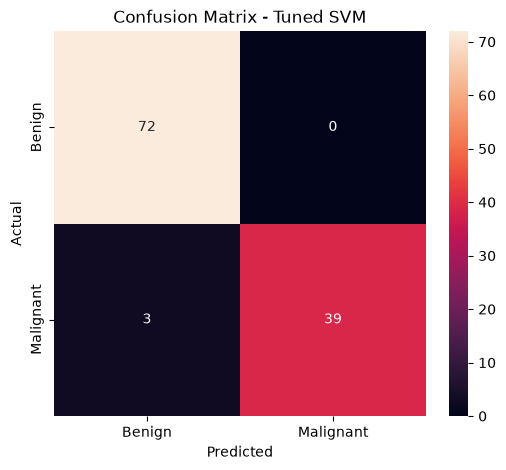

In [81]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Tuned SVM")

plt.show()

In [82]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_svm_tuned,
    target_names=["Benign", "Malignant"]
))

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



# Step 12 : ROC Curve

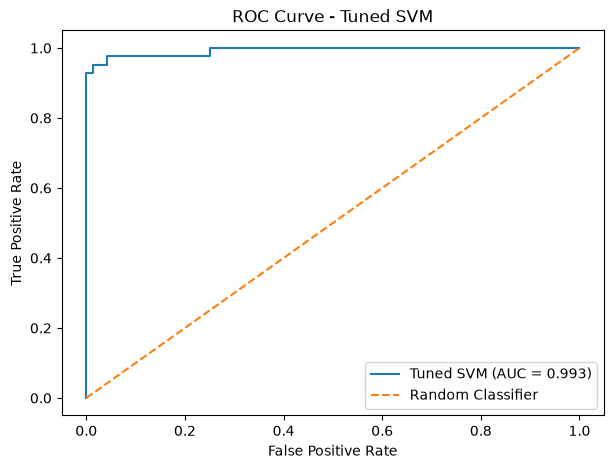

In [83]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_svm_tuned
)

roc_auc = roc_auc_score(
    y_test,
    y_prob_svm_tuned
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Tuned SVM (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned SVM")
plt.legend()
plt.show()

# Step 13 : Save your final pipeline

In [85]:
best_svm = svm_grid.best_estimator_
print(best_svm)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 CalibratedClassifierCV(ensemble=False,
                                        estimator=SVC(C=10, random_state=42)))])


In [88]:
import joblib
import os
import json

# Save
joblib.dump(best_svm, "breast_cancer_svm_pipeline.joblib")

# Save feature names
feature_names = list(X_train.columns)

with open("feature_names.json", "w") as f:
    json.dump(feature_names, f, indent=4)

# Load
loaded_model = joblib.load("breast_cancer_svm_pipeline.joblib")

# Verify
test_predictions = loaded_model.predict(X_test)

print("Model file exists:", os.path.exists("breast_cancer_svm_pipeline.joblib"))
print("Feature count:", len(feature_names))
print("Predictions generated:", len(test_predictions))
print(
    "Predictions identical:",
    (test_predictions == y_pred_svm_tuned).all()
)

Model file exists: True
Feature count: 30
Predictions generated: 114
Predictions identical: True
